# 02.3 · CSP + LDA

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn import __version__ as sklearn_version

def sha256_file(path, chunk_size=8*1024*1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(chunk_size), b''):
            h.update(chunk)
    return h.hexdigest()

print('NumPy:', np.__version__, 'scikit-learn:', sklearn_version)
import mne
from mne.decoding import CSP
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
print('MNE:',mne.__version__)

NumPy: 1.26.4 scikit-learn: 1.5.2
MNE: 1.9.0


In [ ]:
TRYB_TESTOWY = False
USE_ICA = True
USE_ALL_64_CHANNELS = True
ROOT = Path.cwd()  
TAG = ('ica' if USE_ICA else 'bez_ica') + ('_64ch' if USE_ALL_64_CHANNELS else '_19ch')
DATA_DIR = ROOT / (('benchmark_data_demo_' if TRYB_TESTOWY else 'benchmark_data_') + TAG)
RESULTS_BASE = ROOT / (('results_demo_' if TRYB_TESTOWY else 'results_') + TAG)
FOLDS_TO_RUN = [1, 2, 3, 4, 5] 
SEED = 42
THRESHOLD = 0.5  
print('Dane:', DATA_DIR)
print('Foldy:', FOLDS_TO_RUN)
RESULTS_DIR = RESULTS_BASE/'csp_lda'
CSP_COMPONENT_CANDIDATES = (2, 4, 6, 8)
CSP_REG = 0.1  
CSP_NORM_TRACE = False
LDA_SOLVER = 'lsqr'
LDA_SHRINKAGE = 'auto'
print('Model: CSP → LDA; liczby komponentów:', CSP_COMPONENT_CANDIDATES)

Dane: /home/eliza/mgr-phd/benchmark_data_ica_64ch
Foldy: [1, 2, 3, 4, 5]
Model: CSP → LDA; liczby komponentów: (2, 4, 6, 8)


## 2. Wczytanie dokładnie tych samych epok i foldów co w EEGNet

In [3]:
required = [DATA_DIR/'epochs.npz', DATA_DIR/'splits.npz', DATA_DIR/'manifest.json']
for f in required:
    if not f.is_file():
        raise FileNotFoundError(f'Brakuje {f}; uruchom najpierw notebook 01 lub popraw DATA_DIR.')

with np.load(DATA_DIR/'epochs.npz', allow_pickle=False) as d:
    X = d['X'].astype(np.float32, copy=False)
    y = d['y'].astype(np.uint8, copy=False)
    subjects = d['subjects'].astype(str)
    trial_ids = d['trial_ids'].astype(str)
    channel_names = [str(v) for v in d['channel_names']]
with np.load(DATA_DIR/'splits.npz', allow_pickle=False) as d:
    splits = {k: d[k].astype(np.int32) for k in d.files}
manifest = json.loads((DATA_DIR/'manifest.json').read_text(encoding='utf-8'))

assert manifest['demo_mode'] == TRYB_TESTOWY, 'Nieprawidłowy TRYB_TESTOWY względem 01.'
assert bool(manifest['ica']) == USE_ICA, 'Nieprawidłowy USE_ICA względem 01.'
assert manifest['channel_mode'] == ('64' if USE_ALL_64_CHANNELS else '19'), 'Inne kanały niż w 01.'
assert manifest['units'] == 'microvolts', 'Spodziewano się µV.'
assert X.ndim == 3 and X.shape[1] == len(channel_names)
assert len(y) == len(X) == len(subjects) == len(trial_ids)
assert len(set(trial_ids)) == len(trial_ids)
assert set(np.unique(y)) == {0, 1}
assert np.isfinite(X).all(), 'W danych są NaN lub inf.'
assert sorted(set(FOLDS_TO_RUN)) == sorted(FOLDS_TO_RUN)
assert FOLDS_TO_RUN and all(isinstance(f, int) and 1 <= f <= 5 for f in FOLDS_TO_RUN)
assert np.isclose(float(manifest['sampling_rate_hz']), 160.0)

for fold in FOLDS_TO_RUN:
    tr, va, te = (splits[f'{kind}_{fold}'] for kind in ('train', 'val', 'test'))
    assert all(len(np.unique(s)) == len(s) for s in (tr,va,te))
    assert not (set(tr)&set(va) or set(tr)&set(te) or set(va)&set(te))
    ps = [set(subjects[idx]) for idx in (tr,va,te)]
    assert not (ps[0]&ps[1] or ps[0]&ps[2] or ps[1]&ps[2]), f'Fold {fold}: przeciek uczestników!'
    assert all(set(np.unique(y[ix])) == {0,1} for ix in (tr,va,te))

epochs_sha256 = sha256_file(DATA_DIR/'epochs.npz')
splits_sha256 = sha256_file(DATA_DIR/'splits.npz')
print('Dane:', X.shape, 'µV | osoby:', len(np.unique(subjects)))
print('Klasy:', dict(zip(*np.unique(y,return_counts=True))))
print('SHA256 epok:', epochs_sha256[:18], '...')
print('SHA256 foldów:', splits_sha256[:18], '...')
print('Kontrola podziałów i ICA zgodna z notebookiem 01: OK')

Dane: (9844, 64, 481) µV | osoby: 109
Klasy: {0: 4894, 1: 4950}
SHA256 epok: b81d69102d7992c878 ...
SHA256 foldów: ea64542a5ca909a629 ...
Kontrola podziałów i ICA zgodna z notebookiem 01: OK


## 3. Budowa CSP + LDA

In [4]:
def build_csp_lda(n_components):
    return Pipeline([
        ('csp', CSP(
            n_components=int(n_components),
            reg=CSP_REG,
            log=True,
            cov_est='concat',
            transform_into='average_power',
            norm_trace=CSP_NORM_TRACE,
        )),
        ('lda', LinearDiscriminantAnalysis(solver=LDA_SOLVER, shrinkage=LDA_SHRINKAGE)),
    ])

print(build_csp_lda(4))

Pipeline(steps=[('csp', CSP(log=True, reg=0.1)),
                ('lda',
                 LinearDiscriminantAnalysis(shrinkage='auto', solver='lsqr'))])


## 4. Metryki i kontrola wyniku

In [5]:
def score_predictions(y_true, p_left, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    p_left = np.asarray(p_left, dtype=float)
    pred = (p_left >= threshold).astype(int)
    return {
        'roc_auc':float(roc_auc_score(y_true,p_left)),
        'average_precision':float(average_precision_score(y_true,p_left)),
        'accuracy':float(accuracy_score(y_true,pred)),
        'balanced_accuracy':float(balanced_accuracy_score(y_true,pred)),
        'precision':float(precision_score(y_true,pred,zero_division=0)),
        'recall':float(recall_score(y_true,pred,zero_division=0)),
        'f1':float(f1_score(y_true,pred,zero_division=0)),
    }

def prob_left(model, X_input):
    '''Pobierz dokładnie P(y=1), niezależnie od kolejności klas.'''
    classes = np.asarray(model.classes_)
    assert set(classes) == {0,1}, f'Klasy modelu: {classes}'
    return np.asarray(model.predict_proba(X_input)[:, np.where(classes==1)[0][0]], dtype=float)

## 5. Pięć foldów — strojenie na walidacji, testowanie na rozłącznych uczestnikach

In [6]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
fold_results, oof_rows, selected = [], [], {}
for fold in FOLDS_TO_RUN:
    print('\n' + '='*12 + f' FOLD {fold} ' + '='*12)
    folder = RESULTS_DIR / f'fold_{fold}'
    folder.mkdir(parents=True, exist_ok=True)
    tr, va, te = (splits[f'{k}_{fold}'] for k in ('train','val','test'))
    candidate_rows = []
    fitted_candidates = {}
    for n in CSP_COMPONENT_CANDIDATES:
        if n > X.shape[1]:
            continue
        estimator = build_csp_lda(n)
        with mne.use_log_level('ERROR'):
            estimator.fit(X[tr].astype(np.float64), y[tr])
            p_val = prob_left(estimator, X[va].astype(np.float64))
        v = score_predictions(y[va], p_val, THRESHOLD)
        candidate_rows.append({'fold':fold, 'n_components':int(n),
                               'val_roc_auc':v['roc_auc'],
                               'val_balanced_accuracy':v['balanced_accuracy']})
        fitted_candidates[int(n)] = estimator
        print(f'  CSP={n}: validation AUC={v["roc_auc"]:.3f}, bal_acc={v["balanced_accuracy"]:.3f}')

    validation_table = pd.DataFrame(candidate_rows)
    validation_table.to_csv(folder/'validation_candidates.csv', index=False)
    # sortowanie stabilne: AUC malejąco, bal_acc malejąco, liczba komponentów rosnąco
    winner = validation_table.sort_values(
        ['val_roc_auc', 'val_balanced_accuracy', 'n_components'],
        ascending=[False, False, True], kind='stable'
    ).iloc[0]
    best_n = int(winner['n_components'])
    model = fitted_candidates[best_n]
    selected[fold] = best_n
    joblib.dump(model, folder/'model.joblib')

    p_test = prob_left(model, X[te].astype(np.float64))
    fold_score = score_predictions(y[te], p_test, THRESHOLD)
    fold_results.append({'fold':int(fold),'n_test':int(len(te)),
                         'n_components':best_n,**fold_score})
    for ix, probability in zip(te,p_test):
        oof_rows.append({'model':'CSP + LDA','fold':int(fold),
                         'trial_id':str(trial_ids[ix]), 'subject':str(subjects[ix]),
                         'y_true':int(y[ix]), 'p_left':float(probability)})
    print('Wybrano komponentów:', best_n,
          '| test AUC:',round(fold_score['roc_auc'],4),
          '| test bal_acc:',round(fold_score['balanced_accuracy'],4))
    del fitted_candidates, model

pred_df = pd.DataFrame(oof_rows)
fold_df = pd.DataFrame(fold_results)
assert pred_df['trial_id'].is_unique
assert pred_df['p_left'].between(0,1).all()
pred_df.to_csv(RESULTS_DIR/'out_of_fold_predictions.csv',index=False)
fold_df.to_csv(RESULTS_DIR/'fold_metrics.csv',index=False)
display(fold_df.round(4))


============ FOLD 1 ============
  CSP=2: validation AUC=0.548, bal_acc=0.529
  CSP=4: validation AUC=0.602, bal_acc=0.569
  CSP=6: validation AUC=0.661, bal_acc=0.598
  CSP=8: validation AUC=0.654, bal_acc=0.603
Wybrano komponentów: 6 | test AUC: 0.645 | test bal_acc: 0.6058

============ FOLD 2 ============
  CSP=2: validation AUC=0.576, bal_acc=0.545
  CSP=4: validation AUC=0.605, bal_acc=0.573
  CSP=6: validation AUC=0.683, bal_acc=0.625
  CSP=8: validation AUC=0.691, bal_acc=0.641
Wybrano komponentów: 8 | test AUC: 0.6201 | test bal_acc: 0.5795

============ FOLD 3 ============
  CSP=2: validation AUC=0.559, bal_acc=0.550
  CSP=4: validation AUC=0.641, bal_acc=0.606
  CSP=6: validation AUC=0.639, bal_acc=0.593
  CSP=8: validation AUC=0.662, bal_acc=0.613
Wybrano komponentów: 8 | test AUC: 0.6262 | test bal_acc: 0.5883

============ FOLD 4 ============
  CSP=2: validation AUC=0.561, bal_acc=0.525
  CSP=4: validation AUC=0.581, bal_acc=0.549
  CSP=6: validation AUC=0.611, bal_acc=0

,fold,n_test,n_components,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1
0,1,1986,6,0.6450,0.6101,0.6047,0.6058,0.6456,0.4785,0.5496
1,2,1914,8,0.6201,0.6081,0.5794,0.5795,0.5646,0.6904,0.6212
2,3,1984,8,0.6262,0.6084,0.5887,0.5883,0.5880,0.6255,0.6062
3,4,1980,8,0.6667,0.6440,0.6227,0.6234,0.6525,0.5381,0.5898
4,5,1980,8,0.6361,0.6053,0.5939,0.5939,0.5943,0.5943,0.5943


## 6. Jak wyglądają cechy i filtry CSP?

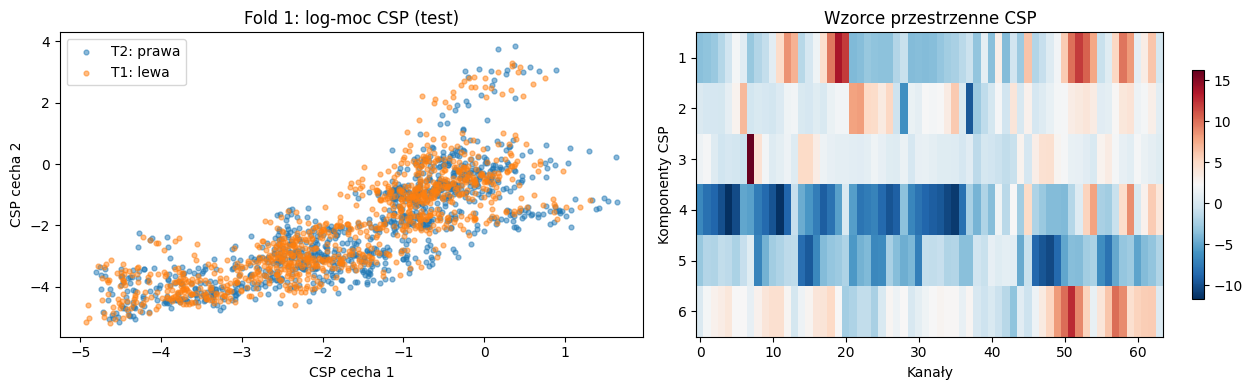

In [7]:
SHOW_FOLD = FOLDS_TO_RUN[0]
model_vis = joblib.load(RESULTS_DIR / f'fold_{SHOW_FOLD}' / 'model.joblib')
chosen = selected[SHOW_FOLD]
_, _, te_vis = (splits[f'{k}_{SHOW_FOLD}'] for k in ('train','val','test'))
with mne.use_log_level('ERROR'):
    features = model_vis.named_steps['csp'].transform(X[te_vis].astype(np.float64))
patterns = model_vis.named_steps['csp'].patterns_[:chosen]
fig, axes = plt.subplots(1,2,figsize=(13,4))
for label, name in [(0,'T2: prawa'), (1,'T1: lewa')]:
    mask = y[te_vis] == label
    axes[0].scatter(features[mask,0],features[mask,1],s=12,alpha=0.5,label=name)
axes[0].set(xlabel='CSP cecha 1',ylabel='CSP cecha 2',title=f'Fold {SHOW_FOLD}: log-moc CSP (test)')
axes[0].legend()
im = axes[1].imshow(patterns,aspect='auto',cmap='RdBu_r')
axes[1].set(xlabel='Kanały',ylabel='Komponenty CSP',title='Wzorce przestrzenne CSP')
axes[1].set_yticks(np.arange(chosen),labels=np.arange(1,chosen+1))
fig.colorbar(im,ax=axes[1],shrink=0.75)
plt.tight_layout();plt.show()

## 7. Macierz pomyłek i krzywa ROC na teście

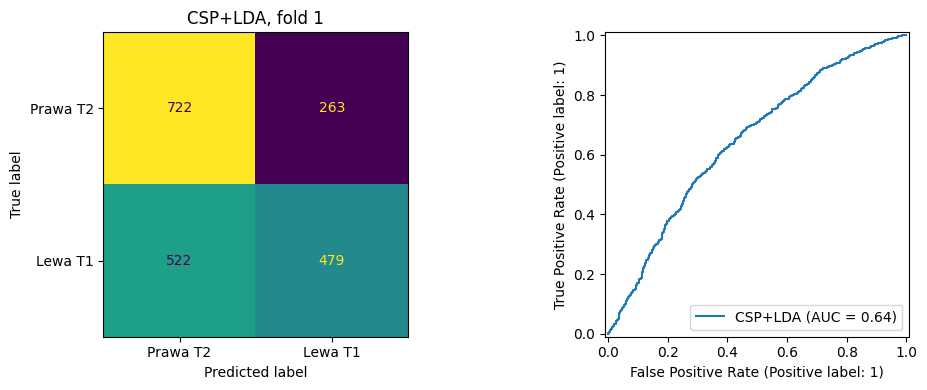

In [8]:
frame = pred_df[pred_df['fold']==SHOW_FOLD]
fig,axes = plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(frame.y_true, (frame.p_left>=THRESHOLD).astype(int),
    ax=axes[0], display_labels=['Prawa T2','Lewa T1'],colorbar=False)
RocCurveDisplay.from_predictions(frame.y_true,frame.p_left,ax=axes[1],name='CSP+LDA')
axes[0].set_title(f'CSP+LDA, fold {SHOW_FOLD}')
plt.tight_layout();plt.show()

## 8. Zapis raportu, weryfikacja zgodności z notebookiem 01 i kolejne kroki

In [9]:
for fold in FOLDS_TO_RUN:
    f = pred_df[pred_df.fold==fold]
    assert set(f.trial_id) == set(trial_ids[splits[f'test_{fold}']]), f'Fold {fold}: niezgodne epoki testowe'
complete = sorted(FOLDS_TO_RUN) == [1,2,3,4,5]
if complete:
    assert len(pred_df)==len(X) and set(pred_df.trial_id)==set(trial_ids)
report = {
    'model':'CSP + LDA', 'dataset_dir':str(DATA_DIR.resolve()),
    'demo_mode':bool(TRYB_TESTOWY), 'use_ica':bool(USE_ICA),
    'n_channels':int(X.shape[1]),'n_trials_in_dataset':int(len(X)),
    'epochs_sha256':epochs_sha256,'splits_sha256':splits_sha256,
    'folds_completed':list(map(int,FOLDS_TO_RUN)),
    'complete_out_of_fold':bool(complete and not TRYB_TESTOWY),
    'seed':SEED, 'decision_threshold':THRESHOLD,
    'csp_components_candidates':list(map(int,CSP_COMPONENT_CANDIDATES)),
    'csp_reg':CSP_REG,'lda_solver':LDA_SOLVER,'lda_shrinkage':LDA_SHRINKAGE,
    'model_selection':'Max walidacyjny ROC-AUC, następnie balanced accuracy, potem mniej komponentów; fit tylko na train',
    'fold_selected_components':{str(k):int(v) for k,v in selected.items()},
    'fold_metrics':fold_results,
    'pooled_completed_test_folds':score_predictions(pred_df.y_true,pred_df.p_left,THRESHOLD),
    'versions':{'python':sys.version.split()[0],'numpy':np.__version__,'mne':mne.__version__, 'scikit_learn':sklearn_version},
}
(RESULTS_DIR/'results.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
print('Zapisano:',RESULTS_DIR/'fold_metrics.csv')
print('Zapisano:',RESULTS_DIR/'out_of_fold_predictions.csv')
print('Następny krok: zaktualizowany notebook 03.')

Zapisano: /home/eliza/mgr-phd/results_ica_64ch/csp_lda/fold_metrics.csv
Zapisano: /home/eliza/mgr-phd/results_ica_64ch/csp_lda/out_of_fold_predictions.csv
Następny krok: zaktualizowany notebook 03.
